# 01 — Exploration DVF Gironde (2021–2025)

Objectif du sprint 1 : comprendre le volume, le schéma et la qualité brute des données avant le nettoyage (sprint 2).

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd
from immo.loader import load_raw

df = load_raw()
print(len(df), 'lignes ;', round(df.memory_usage(deep=True).sum()/1e6), 'Mo')
df.head()

525352 lignes ; 269 Mo


,id_mutation,date_mutation,nature_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,code_postal,code_commune,nom_commune,code_departement,id_parcelle,nombre_lots,type_local,surface_reelle_bati,nombre_pieces_principales,surface_terrain,longitude,latitude
0,2021-502604,2021-01-04,Vente,235000.0,139,RUE SAINT FRANCOIS XAVIER,33170,33192,Gradignan,33,33192000AE0895,0,NaN,NaN,<NA>,628.0,-0.594056,44.777138
1,2021-502605,2021-01-06,Vente,103950.0,26,RUE DU RELAIS,33600,33318,Pessac,33,33318000DI0167,1,Appartement,19.0,1,NaN,-0.606873,44.794243
2,2021-502606,2021-01-05,Vente,214380.0,16,RUE DE CAUSSEROUGE,33000,33063,Bordeaux,33,33063000DR0384,1,Dépendance,NaN,0,NaN,-0.570149,44.832857
3,2021-502606,2021-01-05,Vente,214380.0,2,RUE BRAGARD,33000,33063,Bordeaux,33,33063000DR0384,1,Appartement,38.0,2,NaN,-0.570149,44.832857
4,2021-502607,2021-01-08,Vente,177000.0,131,AV DU MEDOC,33320,33162,Eysines,33,33162000AC0426,1,Appartement,63.0,3,NaN,-0.645310,44.889137


## Volume par année et nature de mutation

In [2]:
print(df.groupby(df.date_mutation.dt.year).size())
df.nature_mutation.value_counts()

date_mutation
2021    118188
2022    119809
2023     92716
2024     82927
2025    111712
dtype: int64


nature_mutation
Vente                                 482710
Vente en l'état futur d'achèvement     34886
Echange                                 5691
Adjudication                             962
Vente terrain à bâtir                    949
Expropriation                            154
Name: count, dtype: int64

## Types de local

In [3]:
df.type_local.value_counts(dropna=False)

type_local
NaN                                         215426
Dépendance                                  126487
Maison                                      101226
Appartement                                  67066
Local industriel. commercial ou assimilé     15147
Name: count, dtype: int64

## Ventes d'appartements/maisons : lignes vs mutations

Plusieurs lignes par mutation (dépendances, plusieurs parcelles, plusieurs biens) → règle de gestion au sprint 2.

In [4]:
v = df[(df.nature_mutation=='Vente') & df.type_local.isin(['Appartement','Maison'])].copy()
n = v.groupby('id_mutation').size()
print(len(v), 'lignes ;', v.id_mutation.nunique(), 'mutations')
print('1 ligne bien :', (n==1).sum(), '; >1 :', (n>1).sum())

167120 lignes ; 125513 mutations
1 ligne bien : 107690 ; >1 : 17823


## Valeurs manquantes

In [5]:
v[['valeur_fonciere','surface_reelle_bati','nombre_pieces_principales','latitude','longitude']].isna().mean().mul(100).round(2)

valeur_fonciere              3.59
surface_reelle_bati          0.00
nombre_pieces_principales    0.00
latitude                     2.50
longitude                    2.50
dtype: float64

## Prix au m² brut (avant nettoyage)

Valeurs extrêmes attendues (prix symboliques, surfaces erronées) → bornes définies au sprint 2.

In [6]:
v['prix_m2'] = v.valeur_fonciere / v.surface_reelle_bati
v.groupby('type_local', observed=True).prix_m2.describe(percentiles=[.01,.5,.99]).round(0)

,count,mean,std,min,1%,50%,99%,max
type_local,,,,,,,,
Appartement,61384.0,18969.0,95261.0,0.0,210.0,4091.0,383660.0,2205735.0
Maison,99739.0,5376.0,27334.0,0.0,429.0,3344.0,37179.0,3215556.0


C:\Users\abdou\AppData\Local\Temp\ipykernel_14676\2881761354.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  v[v.prix_m2.between(500, 12000)].prix_m2.hist(bins=100, by=v.type_local, figsize=(10,3))


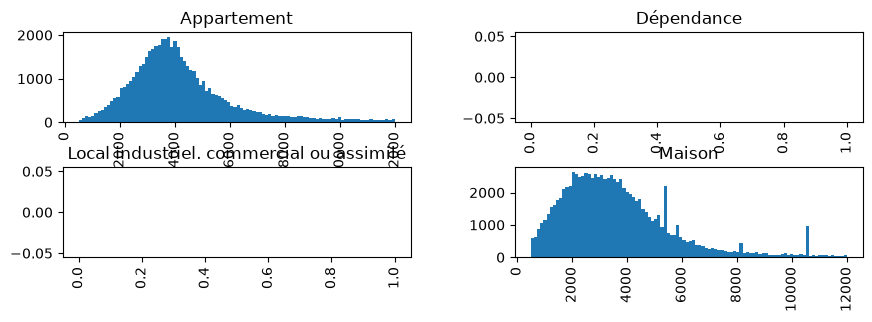

In [7]:
import matplotlib.pyplot as plt
v[v.prix_m2.between(500, 12000)].prix_m2.hist(bins=100, by=v.type_local, figsize=(10,3))
plt.show()